# PC05 — Đánh giá độ bền, lựa chọn phương án và bàn giao nghiên cứu

## Mục tiêu nghiệp vụ
Doanh nghiệp chỉ nên sử dụng nhóm khi hiểu kết quả phụ thuộc vào điều kiện dữ liệu nào. PC05 kiểm tra hai giả định trạng thái, so góc nhìn toàn lịch sử với năm 2022 và tổng hợp đánh đổi giữa các ứng viên.

Phần này không “chữa dữ liệu” để mô hình đẹp hơn. Các kịch bản được công khai là giả định; phạm vi chính vẫn giữ nguyên. Kết luận bàn giao phải nói rõ **được dùng vào việc gì, chưa dùng vào việc gì và cần xác minh gì trước hành động**.

## Chuỗi bằng chứng
PC01 xác nhận phạm vi và tiền → PC02 giải thích đặc trưng → PC03 thực nghiệm mô hình → PC04 đọc ý nghĩa nhóm → PC05 đánh giá điều kiện sử dụng. Mỗi bước có đầu ra và giới hạn riêng; hoàn thành pipeline không đồng nghĩa mọi giả thuyết nghiệp vụ đã được xác minh.


## Cách đọc thuật ngữ và kết quả

- **Recency:** số ngày từ đơn delivered gần nhất đến 31/12/2022.
- **Frequency:** số đơn delivered đủ điều kiện của một khách.
- **Monetary:** tổng tiền sau giảm giá của các đơn đó, chưa là lợi nhuận hoặc thực thu.
- **Cụm:** nhóm khách do thuật toán tạo; mã nhóm chỉ để nhận diện.
- **Mẫu số:** tổng khách hoặc tổng đơn dùng để tính tỷ lệ; luôn đọc đúng phạm vi cạnh bảng.

Các phần không cần công thức được giải thích bằng lời và ví dụ. Khi giữ công thức phân cụm quan trọng, ký hiệu được định nghĩa ngay tại mục đó; không cần suy từ một bảng ký hiệu chung. Dữ liệu ví dụ dùng biến toy_ và không đi vào mô hình thật.


## Chuẩn bị môi trường và nguồn dữ liệu

Notebook tự tìm thư mục dự án và nạp hàm hỗ trợ từ notebook 00. RFM được đối soát trực tiếp với raw/common và CSV kết quả hiện tại; lượt mặc định là combined_v1. Để huấn luyện mới ở PC03, chọn một tên lượt mới qua DATATHON_MODEL_RUN và dùng cùng tên khi đọc PC04–PC06. Chạy từng notebook từ đầu với đúng kernel; không dựa vào biến của notebook khác.


In [1]:
from pathlib import Path
import sys, json
sys.dont_write_bytecode = True
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown

import os

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents)
             if (path / "notebook/ham_dung_chung.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")
sys.path.insert(0, str(ROOT / "notebook"))
from ham_dung_chung import read_notebook, stable_digest, notebook_prefix

# Nạp định nghĩa hỗ trợ riêng, không sửa file Python dùng chung của nhóm.
_support_path = ROOT / 'notebook/05_phan_khuc_khach_hang/00_ham_ho_tro_phan_cum.ipynb'
_support_doc = json.loads(_support_path.read_text(encoding='utf-8'))
for _cell_index, _cell in enumerate(_support_doc['cells']):
    if _cell['cell_type'] == 'code':
        exec(compile(''.join(_cell['source']), f'{_support_path}:cell{_cell_index+1}', 'exec'), globals())

from ham_dung_chung import segmentation_study
sys.dont_write_bytecode = True
Study = phan_cum_tich_hop().Study
share_table = segmentation_study().share_table
concentration = segmentation_study().concentration
distribution = segmentation_study().distribution
from ham_dung_chung import rfm_features
rfm = rfm_features().rfm
from ham_dung_chung import segmentation_transform
feature_matrix = segmentation_transform().feature_matrix
from ham_dung_chung import segmentation_defaults
require = segmentation_defaults().require
FEATURES = segmentation_defaults().FEATURES
CUTOFF = segmentation_defaults().CUTOFF
MODEL_LABEL = os.environ.get("DATATHON_MODEL_RUN", "combined_v1")
study = Study(ROOT, "PC05")
pd.set_option('display.max_columns',20)
print('Phần phân tích:', study.part, '| Lượt mô hình:', MODEL_LABEL)

Phần phân tích: PC05 | Lượt mô hình: combined_v1


## PC05.1 — Kiểm kê đầu vào và nối với phần nghiệp vụ đã nghiệm thu

**Câu hỏi: các kết quả trước có cùng nguồn và phạm vi để dùng tiếp không?**

Kiểm đường dẫn, trạng thái hoàn tất, nguồn và các notebook PC01–PC04. Liên hệ các nội dung kinh doanh NV01, NV02, NV06 và TH01 để biết chỉ tiêu nào có thể tham khảo.

NV02 có thống kê khách theo nhiều trạng thái; phân cụm chính chỉ dùng đơn delivered. Không thay số khách của NV02 bằng số khách RFM. Chỉ đối chiếu trực tiếp khi cùng cấp dữ liệu, tập khách/đơn, thời gian và trạng thái.

Lần chạy phân cụm không chứng nhận lại toàn bộ kết luận kinh doanh. Chứng cứ kỹ thuật cho thấy dữ liệu nhất quán, chưa phải thước đo đủ của giá trị nghiệp vụ.


In [2]:
model_manifest=study.use_model(MODEL_LABEL)
rows = []
for number in range(1, 5):
    part = f"PC{number:02}"
    path = next(
        (ROOT / "notebook/05_phan_khuc_khach_hang").glob(f"{part}_*.ipynb")
    )
    cells = read_notebook(path)["cells"]
    saved = [cell for cell in cells if cell["cell_type"] == "code"]
    rows.append({
        "Phần": part,
        "Notebook": path.name,
        "Ô code đã lưu kết quả": sum(c.get("execution_count") is not None for c in saved),
    })
study.table("input_inventory", "Kiểm kê notebook PC01–PC04", pd.DataFrame(rows))
upstream=[]
for name,marker,usage,limit in [
 ('NV01_phan_tich_ban_hang.ipynb','NV01.6','Đối chiếu cơ cấu danh mục/Net delivered trong PC04','Không coi lượng/Net là lợi nhuận'),
 ('NV02_phan_tich_khach_hang.ipynb','NV02','Kế thừa câu hỏi khách hàng; phân biệt90246 khách có đơn với85115 khách RFM','Không đổi mẫu số NV02 hoặc gọi đó là phân cụm đã hoàn thành'),
 ('NV06_phan_tich_khuyen_mai_marketing.ipynb','NV06.6','Kế thừa giới hạn mã/khuyến mãi khi đọc hành vi nhóm','Không quy khác biệt mô tả thành uplift/ROI'),
 ('TH01_tong_hop_va_doi_soat_NV01_NV06.ipynb','TH01.5','Dẫn tới tổng hợp nghiệp vụ hiện hành của bản mới','Không đóng các vấn đề thiếu chứng từ hoặc thay kết luận Bài toán1')]:
 path=ROOT/'notebook/04_phan_tich_kinh_doanh'/name;doc=read_notebook(path);require(any(marker in ''.join(cell.get('source',[])) for cell in doc['cells']),'Thiếu phần hiện hành '+marker)
 upstream.append({'Nguồn bản mới':name,'Phần hiện hành':marker,'Kế thừa cho phân cụm':usage,'Giới hạn giữ nguyên':limit})
study.table('upstream_business_handoff','Liên hệ Bài toán2 với các phần cập nhật của nhóm',pd.DataFrame(upstream))
study.note('Các notebookkinhdoanh được đọc như tài liệu/nguồn phân tích đã bàn giao, không tái chạy hoặc sửa ở đây. Lượt mô hình đang đọc được ghi ở ô thiết lập. Bộ đặc trưng và nhãn lưu cùng dữ liệu mô hình.')

,Phần,Notebook,Ô code đã lưu kết quả
0,PC01,PC01_pham_vi_va_xay_dung_rfm.ipynb,11
1,PC02,PC02_phan_tich_rfm_va_dac_trung.ipynb,13
2,PC03,PC03_thuc_nghiem_va_lua_chon_mo_hinh.ipynb,16
3,PC04,PC04_ho_so_nhom_va_y_nghia_nghiep_vu.ipynb,13


,Nguồn bản mới,Phần hiện hành,Kế thừa cho phân cụm,Giới hạn giữ nguyên
0,NV01_phan_tich_ban_hang.ipynb,NV01.6,Đối chiếu cơ cấu danh mục/Net delivered trong ...,Không coi lượng/Net là lợi nhuận
1,NV02_phan_tich_khach_hang.ipynb,NV02,Kế thừa câu hỏi khách hàng; phân biệt90246 khá...,Không đổi mẫu số NV02 hoặc gọi đó là phân cụm ...
2,NV06_phan_tich_khuyen_mai_marketing.ipynb,NV06.6,Kế thừa giới hạn mã/khuyến mãi khi đọc hành vi...,Không quy khác biệt mô tả thành uplift/ROI
3,TH01_tong_hop_va_doi_soat_NV01_NV06.ipynb,TH01.5,Dẫn tới tổng hợp nghiệp vụ hiện hành của bản mới,Không đóng các vấn đề thiếu chứng từ hoặc thay...


Các notebookkinhdoanh được đọc như tài liệu/nguồn phân tích đã bàn giao, không tái chạy hoặc sửa ở đây. Lượt mô hình đang đọc được ghi ở ô thiết lập. Bộ đặc trưng và nhãn lưu cùng dữ liệu mô hình.

## PC05.2 — Độ nhạy trạng thái với scaler và tâm giữ cố định

**Câu hỏi: thay cách chọn đơn có làm cùng một khách đổi nhóm nhiều không?**

Giữ nguyên scaler và tâm của mô hình chính. Tính lại RFM theo hai kịch bản: bỏ delivered thiếu shipment; hoặc giả định thêm shipped có ngày giao không sau 31/12/2022. Không đổi trạng thái nguồn và không coi giả định thứ hai là giao thực tế đã xác nhận.

Chỉ so nhãn trên những khách có mặt ở cả tập chính và tập kịch bản. Ví dụ có 100 khách ban đầu, còn 90 khách chung và 3 người đổi nhóm thì tỷ lệ là 3 chia 90, khoảng 3,33%. Mười khách mất điều kiện được báo riêng, không tính là đổi nhóm.

Vì giữ nguyên tâm và mã tâm, so trực tiếp nhãn là phù hợp. Nếu fit lại mô hình thì ranh giới và số nhãn có thể đổi, cần đối chiếu phân hoạch bằng ARI. Ít đổi nhóm chưa chứng minh trạng thái nguồn đúng.


### Minh họa tính tay có kiểm chứng — tách khỏi dữ liệu thật

Ô sau dùng dữ liệu giả lập với biến `toy_`, đối chiếu kết quả mong đợi hoặc thư viện. Chúng không tham gia huấn luyện. Sau ví dụ là phép phân tích trên dữ liệu dự án.

In [3]:
# VÍ DỤ GIẢ LẬP: báo khách chung và thay đổi nhãn riêng biệt.
toy_base=np.r_[np.zeros(45,dtype=int),np.ones(45,dtype=int)];toy_case=toy_base.copy();toy_case[:3]=1
toy_changed=int((toy_base!=toy_case).sum());toy_rate=toy_changed/len(toy_base);assert np.isclose(toy_rate,3/90)
study.table('VD10_sensitivity','Ví dụ giả lập — mẫu số độ nhạy',pd.DataFrame([{'Khách tập chính':100,'Khách chung':90,'Khách mất điều kiện':10,'Khách chung đổi nhãn':toy_changed,'Tỷ lệ đúng trên khách chung':toy_rate,'Tỷ lệ3/100 không đúng mục tiêu':toy_changed/100}]))

,Khách tập chính,Khách chung,Khách mất điều kiện,Khách chung đổi nhãn,Tỷ lệ đúng trên khách chung,Tỷ lệ3/100 không đúng mục tiêu
0,100,90,10,3,0.033333,0.03


,Khách tập chính,Khách chung,Khách mất điều kiện,Khách chung đổi nhãn,Tỷ lệ đúng trên khách chung,Tỷ lệ3/100 không đúng mục tiêu
0,100,90,10,3,0.033333,0.03


,scenario,Số đơn,Số khách,common_customers,removed_customers,added_customers,customers_with_changed_RFM,ari_frozen_model,share_changed_frozen_labels
0,remove_delivered_without_shipment,516192,85095,85095,20,0,493,0.996302,0.001105
1,hypothesis_add_shipped_with_delivery_date,530478,85735,85115,0,620,11169,0.961403,0.012477


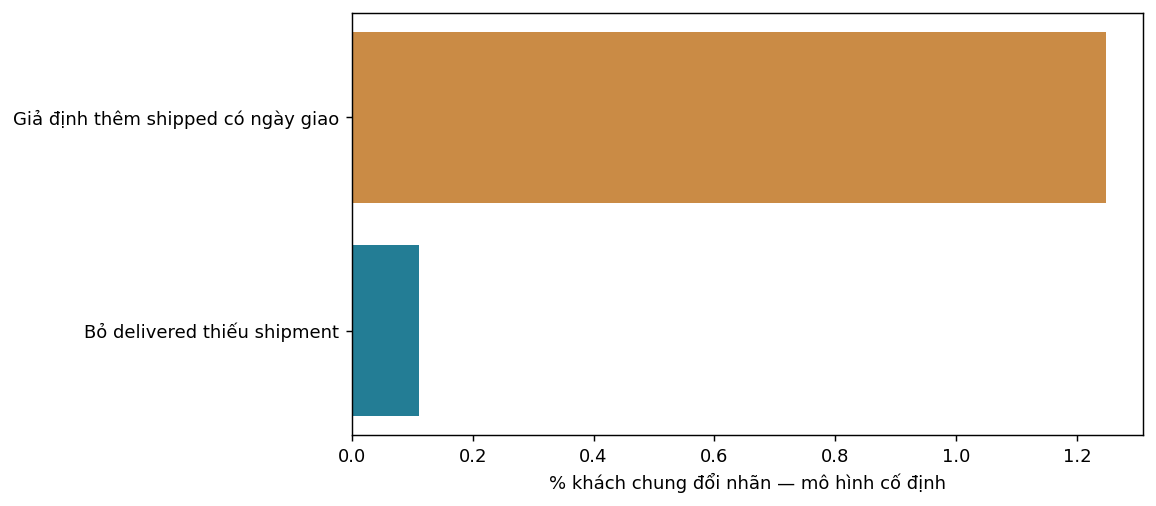

remove_delivered_without_shipment: 85,095 khách chung, thêm 0, bớt 20; 493 khách thay RFM; 0.11% đổi nhãn; ARI=0.9963. Ít đổi nhóm không chứng minh trạng thái đúng.

hypothesis_add_shipped_with_delivery_date: 85,115 khách chung, thêm 620, bớt 0; 11,169 khách thay RFM; 1.25% đổi nhãn; ARI=0.9614. Ít đổi nhóm không chứng minh trạng thái đúng.

In [4]:
phan_cum_tich_hop().ensure_status_sensitivity(ROOT,MODEL_LABEL)
s=pd.read_csv(study.modelbase/'status_sensitivity.csv')
study.table('status_sensitivity','Hai kịch bản độ nhạy',s.drop(columns='method'))
fig,ax=plt.subplots(figsize=(9,4));ax.barh(['Bỏ delivered thiếu shipment','Giả định thêm shipped có ngày giao'],s.share_changed_frozen_labels*100,color=['#237d95','#ca8b45']);ax.set(xlabel='% khách chung đổi nhãn — mô hình cố định');study.fig('status_sensitivity','Tỷ lệ đổi nhãn trên khách chung',fig)
for row in s.itertuples():study.note(f'{row.scenario}: {row.common_customers:,} khách chung, thêm {row.added_customers:,}, bớt {row.removed_customers:,}; {row.customers_with_changed_RFM:,} khách thay RFM; {row.share_changed_frozen_labels:.2%} đổi nhãn; ARI={row.ari_frozen_model:.4f}. Ít đổi nhóm không chứng minh trạng thái đúng.')

## PC05.3 — Cửa sổ thời gian: tích lũy khác hoạt động gần đây

**Câu hỏi: toàn lịch sử và riêng năm 2022 mô tả cùng một điều không?**

Không. Toàn lịch sử phản ánh mua tích lũy đến 31/12/2022. Năm 2022 chỉ giữ đơn từ 01/01/2022 đến hết 31/12/2022. Khách có đơn trong năm 2022 giữ cùng lần mua cuối, nhưng số đơn và tiền năm đó không lớn hơn tổng lịch sử.

Nếu dùng một cửa sổ đúng năm ngày kết thúc 31/12 thì chọn từ 27/12 đến 31/12, tính cả hai đầu. Ví dụ trong code minh họa quy tắc ngày, không đòi hỏi theo dõi ký hiệu khoảng thời gian.

Bước này mới so tập khách và đặc trưng, chưa huấn luyện mô hình riêng cho năm 2022. Không kết luận phạm vi nào chính xác hơn chỉ từ số khách; muốn đánh giá mô hình theo cửa sổ phải có thí nghiệm riêng.


In [5]:
# VÍ DỤ GIẢ LẬP: cửa sổ có cả hai đầu.
toy_T=pd.Timestamp('2022-12-31');toy_L=5;toy_start=toy_T-pd.Timedelta(days=toy_L-1);toy_dates=pd.date_range(toy_start,toy_T,freq='D');assert len(toy_dates)==toy_L
study.table('VD11_window','Ví dụ giả lập — cửa sổ5ngày kết thúc31/12',pd.DataFrame({'Ngày được chọn':toy_dates.date}))

,Ngày được chọn
0,2022-12-27
1,2022-12-28
2,2022-12-29
3,2022-12-30
4,2022-12-31


,Ngày được chọn
0,2022-12-27
1,2022-12-28
2,2022-12-29
3,2022-12-30
4,2022-12-31


In [6]:
o=study.orders();delivered=o.loc[o.order_status.eq('delivered') & o.order_date.le(CUTOFF)];recent=rfm(delivered.loc[delivered.order_date.ge('2022-01-01')])
rows=[]
for name,f in [('Toàn lịch sử',study.f),('Năm2022',recent)]:rows.append({'Phạm vi':name,'Số khách':len(f),'Tổng đơn':int(f.Frequency.sum()),'Tỷ trọng một đơn':f.Frequency.eq(1).mean(),'R trung vị':f.Recency.median(),'F trung vị':f.Frequency.median(),'M trung vị':f.Monetary.astype(float).median()})
study.table('window_feature_comparison','Đối chiếu phạm vi/đặc trưng — chưa so mô hình',pd.DataFrame(rows))
common=recent.merge(study.f,on='customer_id',suffixes=('_2022','_history'),validate='one_to_one')
require(common.Recency_2022.eq(common.Recency_history).all(),'R khách chung phải bằng nhau')
require(common.Frequency_history.ge(common.Frequency_2022).all(),'F lịch sử không được nhỏ hơn')
study.note('Cửa sổ năm2022 mô tả hoạt động gần cuối; toàn lịch sử mô tả tích lũy. Chưa thực nghiệm mô hình cửa sổ này trong PC01–PC05; đây là đầu vào nghiên cứu tiếp, không tự thay kết quả chính.')

,Phạm vi,Số khách,Tổng đơn,Tỷ trọng một đơn,R trung vị,F trung vị,M trung vị
0,Toàn lịch sử,85115,516716,0.268378,1142.0,3.0,79730.85
1,Năm2022,20389,27688,0.747560,185.0,1.0,30099.45


Cửa sổ năm2022 mô tả hoạt động gần cuối; toàn lịch sử mô tả tích lũy. Chưa thực nghiệm mô hình cửa sổ này trong PC01–PC05; đây là đầu vào nghiên cứu tiếp, không tự thay kết quả chính.

## PC05.4 — Lựa chọn phương án cho mục tiêu nghiệp vụ hiện tại

**Câu hỏi: vì sao giữ một phương án khi các chỉ số không cùng chọn nó?**

Quyết định cho báo cáo mô tả dựa trên dữ liệu đã kiểm chứng, chỉ số nội bộ, quy mô cụm, kiểm seed, hồ sơ và độ nhạy. Không có nhãn đúng hoặc trọng số kinh doanh để chứng minh một cách chia tối ưu tuyệt đối.

Nếu hai cụm có Silhouette cao hơn nhưng ba cụm có DB thuận lợi và nhóm trung gian dễ giải thích, phải nói rõ đánh đổi. Nếu bốn cụm thêm chi tiết chưa có mục tiêu riêng, không chọn chỉ để bài trông nhiều nhóm hơn.

Khuyến nghị kỹ thuật chưa phải quyết định phân bổ ngân sách. Khi mục tiêu sử dụng thay đổi, số cụm phù hợp cũng có thể thay đổi mà không phủ nhận các quan sát hiện tại.


In [7]:
phan_cum_tich_hop().ensure_main_experiments(ROOT,MODEL_LABEL)
grid=pd.read_csv(study.modelbase/'experiment_grid.csv');variant=model_manifest['selected']['variant'];t=grid.loc[(grid.variant==variant)&grid.k.isin([2,3,4])].copy()
t['Đánh đổi']=['Ít nhóm, dễ dùng; có thể gộp các mức hoạt động' if k==2 else 'Thêm một góc phân biệt; cần hồ sơ PC04' if k==3 else 'Chi tiết hơn; cân nhắc tách đuôi và độ phức tạp' for k in t.k]
study.table('decision_candidates','Ma trận phương án cùng phép biến đổi',t)
k=model_manifest['selected']['k'];study.note(f'Khuyến nghị cho mục tiêu mô tả hiện tại: {variant}, k={k}. Có căn cứ từ chỉ số, seed và hồ sơ; chưa chứng minh tối ưu kinh doanh. Nếu mục tiêu thay đổi, k2/k4 vẫn là ứng viên hợp lệ. Không dùng tổng hạng thay xác nhận nghiệp vụ.')
selected=t.loc[t.k.eq(k)].iloc[0];r2=t.loc[t.k.eq(2)].iloc[0];r4=t.loc[t.k.eq(4)].iloc[0]
study.note(f'Đánh đổi định lượng: k2 có Silhouette {r2.silhouette_sample:.4f} cao hơn k3 {selected.silhouette_sample:.4f}, nhưng DB k3={selected.davies_bouldin_full:.4f} thấp hơn k2={r2.davies_bouldin_full:.4f}. k4 có Silhouette {r4.silhouette_sample:.4f} và cụm nhỏ nhất {r4.min_cluster_share:.2%}. PC04 cho thấy k3 phân biệt nhóm lâu chưa mua/ít đơn, nhóm trung gian và nhóm mua nhiều/Net cao hơn; k4 thêm chi tiết đuôi chưa có mục tiêu riêng. Vì vậy giữ k3 cho báo cáo mô tả, không gọi tốt nhất cho mọi mục tiêu.')

TN1, k=2: silhouette=0.5171; min_share=22.25%
TN1, k=3: silhouette=0.4589; min_share=12.07%
TN1, k=4: silhouette=0.4416; min_share=4.42%
TN1, k=5: silhouette=0.4007; min_share=3.99%
TN1, k=6: silhouette=0.4008; min_share=1.96%
TN1, k=7: silhouette=0.3911; min_share=1.09%
TN1, k=8: silhouette=0.3970; min_share=0.94%
TN2, k=2: silhouette=0.4687; min_share=49.85%
TN2, k=3: silhouette=0.3852; min_share=29.65%
TN2, k=4: silhouette=0.3330; min_share=21.05%
TN2, k=5: silhouette=0.3410; min_share=15.11%
TN2, k=6: silhouette=0.3296; min_share=10.65%
TN2, k=7: silhouette=0.3199; min_share=9.04%
TN2, k=8: silhouette=0.3181; min_share=7.51%


,Thí nghiệm,Số cụm,Silhouette mẫu,Davies–Bouldin toàn tập,Inertia,Tỷ trọng cụm nhỏ nhất,Tỷ trọng cụm lớn nhất,seconds,Đánh đổi
0,TN1,2,0.517096,0.783078,130752.023217,0.222511,0.777489,0.828,"Ít nhóm, dễ dùng; có thể gộp các mức hoạt động"
1,TN1,3,0.458908,0.743269,75607.122860,0.120719,0.473971,0.797,Thêm một góc phân biệt; cần hồ sơ PC04
2,TN1,4,0.441575,0.748110,53509.804174,0.044234,0.402867,1.187,Chi tiết hơn; cân nhắc tách đuôi và độ phức tạp


Khuyến nghị cho mục tiêu mô tả hiện tại: TN1, k=3. Có căn cứ từ chỉ số, seed và hồ sơ; chưa chứng minh tối ưu kinh doanh. Nếu mục tiêu thay đổi, k2/k4 vẫn là ứng viên hợp lệ. Không dùng tổng hạng thay xác nhận nghiệp vụ.

Đánh đổi định lượng: k2 có Silhouette 0.5171 cao hơn k3 0.4589, nhưng DB k3=0.7433 thấp hơn k2=0.7831. k4 có Silhouette 0.4416 và cụm nhỏ nhất 4.42%. PC04 cho thấy k3 phân biệt nhóm lâu chưa mua/ít đơn, nhóm trung gian và nhóm mua nhiều/Net cao hơn; k4 thêm chi tiết đuôi chưa có mục tiêu riêng. Vì vậy giữ k3 cho báo cáo mô tả, không gọi tốt nhất cho mọi mục tiêu.

## PC05.5 — Giới hạn dữ liệu, phương pháp và việc chưa làm

**Câu hỏi: kết quả chưa cho phép khẳng định những gì?**

Chưa biết lịch sử đổi trạng thái và thời điểm dữ liệu sẵn có, nên không tái dựng được đánh giá lịch sử đúng thời điểm. Chưa xác minh đầy đủ quyết toán và chi phí, nên Monetary không được gọi là thực thu hoặc lợi nhuận.

Frequency/Monetary tích lũy chịu ảnh hưởng thời gian quan sát. Các chỉ số được dùng chọn cấu hình, chưa có tập thời gian tương lai để đánh giá; không gọi đó là độ chính xác dự báo. Chưa thử chương trình chăm sóc nên chưa có bằng chứng tăng doanh thu.

Báo cáo nghiệm thu chỉ ghi phạm vi đã thực sự kiểm tra. Không biến kết quả kiểm thử của một phiên bản hoặc môi trường cũ thành khẳng định toàn bộ dự án hiện tại đã đạt. Trước hành động cần xác minh định nghĩa, điều kiện khách, ngân sách và thiết kế đo hiệu quả.


In [8]:
limits=pd.DataFrame([
{'Nhóm':'Nguồn','Giới hạn':'Không lịch sử status/updated_at/extraction time','Hệ quả':'Không tái dựng chuyển trạng thái/backtest as-of','Cần thêm':'Log sự kiện hoặc từ điển nghiệp vụ'},
{'Nhóm':'Nguồn','Giới hạn':'Payment/delivery_date chưa xác nhận ngữ nghĩa','Hệ quả':'Không tự sửa status, không gọi M là thực thu','Cần thêm':'Định nghĩa và chứng từ'},
{'Nhóm':'Phương pháp','Giới hạn':'F/M tích lũy chịu cơ hội/thời gian quan sát','Hệ quả':'Không đồng nhất với trung thành/tiềm năng','Cần thêm':'Cohort/cửa sổ và lịch sử hợp lệ'},
{'Nhóm':'Phương pháp','Giới hạn':'Metrics dùng chọn mô hình, không holdout','Hệ quả':'Không gọi là độ chính xác dự báo','Cần thêm':'Ổn định theo thời gian/đánh giá sử dụng'},
{'Nhóm':'Chưa làm','Giới hạn':'Đã đối chứng DBSCAN/GMM trên mẫu; chưa RFM mở rộng','Hệ quả':'Đối chứng trên mẫu chưa thay huấn luyện toàn tập hoặc thiết kế đặc trưng mới','Cần thêm':'Thí nghiệm riêng nếu có lý do'},
{'Nhóm':'Chưa làm','Giới hạn':'Chưa kiểm hiệu quả chăm sóc/ưu đãi','Hệ quả':'Hành động mới là giả thuyết','Cần thêm':'Thẩm định và thử nghiệm có đối chứng'}])
study.table('limitations','Ma trận giới hạn và điều kiện',limits)
study.note('Kết quả sẵn sàng cho báo cáo phân cụm mô tả có giới hạn. Chưa sẵn sàng gọi churn/VIP/CLV hoặc triển khai quyết định kinh doanh tự động.')

,Nhóm,Giới hạn,Hệ quả,Cần thêm
0,Nguồn,Không lịch sử status/updated_at/extraction time,Không tái dựng chuyển trạng thái/backtest as-of,Log sự kiện hoặc từ điển nghiệp vụ
1,Nguồn,Payment/delivery_date chưa xác nhận ngữ nghĩa,"Không tự sửa status, không gọi M là thực thu",Định nghĩa và chứng từ
2,Phương pháp,F/M tích lũy chịu cơ hội/thời gian quan sát,Không đồng nhất với trung thành/tiềm năng,Cohort/cửa sổ và lịch sử hợp lệ
3,Phương pháp,"Metrics dùng chọn mô hình, không holdout",Không gọi là độ chính xác dự báo,Ổn định theo thời gian/đánh giá sử dụng
4,Chưa làm,Đã đối chứng DBSCAN/GMM trên mẫu; chưa RFM mở ...,Đối chứng trên mẫu chưa thay huấn luyện toàn t...,Thí nghiệm riêng nếu có lý do
5,Chưa làm,Chưa kiểm hiệu quả chăm sóc/ưu đãi,Hành động mới là giả thuyết,Thẩm định và thử nghiệm có đối chứng


Kết quả sẵn sàng cho báo cáo phân cụm mô tả có giới hạn. Chưa sẵn sàng gọi churn/VIP/CLV hoặc triển khai quyết định kinh doanh tự động.

## PC05.6 — Bàn giao nghiên cứu có thể dùng lại

**Câu hỏi: người nhận cần gì để hiểu và dùng kết quả?**

Cần biết ai được phân nhóm, đơn nào được chọn, RFM tính thế nào, vì sao giữ mô hình hiện tại và giới hạn còn mở. Notebook giữ giải thích, bảng, hình và kết quả kiểm tra ngay cạnh code.

Trong model chỉ giữ CSV phân cụm và JSON tham số mô hình đã chọn. RFM chi tiết, hành vi bổ trợ và các bảng đánh giá được dựng lại từ raw/common khi cần, không lưu thành hàng chục file kết quả. Notebook hỗ trợ 00 là mã nguồn cần giữ; file Python gốc của nhóm không bị sửa.

Báo cáo phụ chỉ xuất khi chủ động bật và có thể xóa. Nghiên cứu hiện chưa chứng minh chiến lược chăm sóc làm tăng doanh thu; kiểm theo thời gian và thử nghiệm hành động là các bước tiếp theo.


In [9]:
profiles=pd.read_csv(study.modelbase/'cluster_profiles.csv')
study.table('final_profiles','Hồ sơ được chọn để bàn giao',profiles)
for row in profiles.itertuples():study.note(f'Nhóm {row.cluster}: {row.customers:,} khách ({row.customer_share:.2%}), R trung vị {row.Recency_median:.0f} ngày, F {row.Frequency_median:.0f} đơn, M {row.Monetary_median:,.2f} ĐVT nguồn; đóng góp {row.Monetary_share:.2%} Net delivered. Đây là mô tả cùng tập nguồn, không là giá trị khách tương lai.')
study.note('Tổng hợp: thiết kế đã kiểm phạm vi/tiền, phân bố/ngoại lệ, 14 cấu hình, seed, đối chứng mẫu, hồ sơ trong nhóm và độ nhạy trạng thái. Không xóa bất thường để làm metrics đẹp. Giữ RFM delivered làm chính; mọi trạng thái bổ trợ diễn giải. Mở rộng cửa sổ/đặc trưng là bước nghiên cứu tiếp có kiểm soát.')

,Nhóm,Số khách,R trung vị,F trung vị,M trung vị,Tổng Net,TB tỷ trọng cancelled/khách,TB tỷ trọng returned/khách,TB tỷ trọng có returns/khách,TB tỷ trọng thiếu shipment/khách,Số SP khác nhau trung vị,Tỷ trọng khách,Tỷ trọng Net
0,0,34498,2307.0,1.0,29651.965,1.435208e+09,0.061616,0.036944,0.036891,0.000000,2.0,0.405310,0.114650
1,1,40342,598.0,5.0,124473.995,5.614874e+09,0.075082,0.045350,0.045252,0.001875,6.0,0.473971,0.448538
2,2,10275,244.0,19.0,477244.080,5.468093e+09,0.082397,0.050480,0.050340,0.000975,20.0,0.120719,0.436812


Nhóm 0: 34,498 khách (40.53%), R trung vị 2307 ngày, F 1 đơn, M 29,651.97 ĐVT nguồn; đóng góp 11.46% Net delivered. Đây là mô tả cùng tập nguồn, không là giá trị khách tương lai.

Nhóm 1: 40,342 khách (47.40%), R trung vị 598 ngày, F 5 đơn, M 124,473.99 ĐVT nguồn; đóng góp 44.85% Net delivered. Đây là mô tả cùng tập nguồn, không là giá trị khách tương lai.

Nhóm 2: 10,275 khách (12.07%), R trung vị 244 ngày, F 19 đơn, M 477,244.08 ĐVT nguồn; đóng góp 43.68% Net delivered. Đây là mô tả cùng tập nguồn, không là giá trị khách tương lai.

Tổng hợp: thiết kế đã kiểm phạm vi/tiền, phân bố/ngoại lệ, 14 cấu hình, seed, đối chứng mẫu, hồ sơ trong nhóm và độ nhạy trạng thái. Không xóa bất thường để làm metrics đẹp. Giữ RFM delivered làm chính; mọi trạng thái bổ trợ diễn giải. Mở rộng cửa sổ/đặc trưng là bước nghiên cứu tiếp có kiểm soát.

## Tổng kết nghiệp vụ và điều kiện bàn giao

Các đoạn dưới được sinh từ kết quả thật của phần phân tích, giữ riêng quan sát và giả thuyết.

In [10]:
study.note("### Kết luận điều hành và mức sẵn sàng sử dụng")
study.note(f'Nghiên cứu giữ RFM delivered toàn lịch sử làm phương án chính, đề xuất {study.modelmanifest["selected"]["variant"]}/k={study.modelmanifest["selected"]["k"]} cho báo cáo mô tả. Có đối thủ, hồ sơ, kiểm seed và độ nhạy để người đọc đánh giá; chưa chứng minh hiệu quả phân bổ ngân sách hay giá trị khách tương lai. Bước trước hành động là xác minh định nghĩa trọng yếu, đặt mục tiêu và chọn KPI có mẫu số rõ. Xem docs/phan_khuc/nghiem_thu/acceptance.json để biết phạm vi kiểm thử thực tế của bản ghép; không suy rằng đã kiểm thử toàn bộ dự án.')

### Kết luận điều hành và mức sẵn sàng sử dụng

Nghiên cứu giữ RFM delivered toàn lịch sử làm phương án chính, đề xuất TN1/k=3 cho báo cáo mô tả. Có đối thủ, hồ sơ, kiểm seed và độ nhạy để người đọc đánh giá; chưa chứng minh hiệu quả phân bổ ngân sách hay giá trị khách tương lai. Bước trước hành động là xác minh định nghĩa trọng yếu, đặt mục tiêu và chọn KPI có mẫu số rõ. Xem docs/phan_khuc/nghiem_thu/acceptance.json để biết phạm vi kiểm thử thực tế của bản ghép; không suy rằng đã kiểm thử toàn bộ dự án.

## Kiểm chứng và hoàn tất phân tích

Kiểm dữ liệu nguồn không thay đổi và hoàn tất các phép tính trong notebook. Bảng và biểu đồ hiển thị tại chỗ. Mặc định không xuất báo cáo phụ; chỉ bật xuất khi thực sự cần. Trong model chỉ giữ CSV kết quả và JSON tham số. Các bảng đánh giá chỉ tính để hiển thị trong notebook, độc lập với reports.


### PC05.9. Độ nhạy của bốn thuật toán — phần bổ sung từ bản mới

**Câu hỏi: bốn thuật toán nhạy với những thay đổi nào?**

Trên mẫu 5.000 khách: đổi seed cho K-Means/GMM; chọn ba mẫu con 80%; giới hạn Frequency/Monetary tại P99 trên bản sao; đổi cách ghép của Hierarchical và bán kính DBSCAN. Khi đổi mẫu, giữ seed mô hình và scaler tham chiếu để không trộn nhiều nguyên nhân.

Thử P99 fit lại scaler và mô hình, nên đo tác động kết hợp; đây không phải chính sách cắt ngọn của dữ liệu chính. DBSCAN phải đọc cùng số cụm, nhiễu và quy mô: ARI cao chưa đủ nếu gần hết khách nằm trong một nhóm. Báo riêng ARI gồm nhiễu và ARI trên khách không nhiễu chung; chỉ số có thể không xác định nếu không còn đủ nhóm.

Để xem ranh giới K-Means, so khoảng cách tới hai tâm gần nhất. Hai khoảng cách càng sát nhau thì khách càng khó phân biệt theo tiêu chí này. Chọn 5% có mức chênh tương đối thấp nhất để đọc hồ sơ; 250 trên 5.000 là kết quả của quy tắc chọn 5%, không phải 250 nhãn sai hoặc xác suất phân sai.


Đối chứng K-Means {'k': 2} S= 0.5172
Đối chứng Hierarchical {'k': 2} S= 0.5776
Đối chứng GMM {'k': 2} S= 0.4031
Đối chứng K-Means {'k': 3} S= 0.4595
Đối chứng Hierarchical {'k': 3} S= 0.391
Đối chứng GMM {'k': 3} S= 0.2777
Đối chứng K-Means {'k': 4} S= 0.4401
Đối chứng Hierarchical {'k': 4} S= 0.3597
Đối chứng GMM {'k': 4} S= 0.1637
Đối chứng K-Means {'k': 5} S= 0.4005
Đối chứng Hierarchical {'k': 5} S= 0.356
Đối chứng GMM {'k': 5} S= 0.0944
Đối chứng K-Means {'k': 6} S= 0.4002
Đối chứng Hierarchical {'k': 6} S= 0.3403
Đối chứng GMM {'k': 6} S= 0.0883
Đối chứng K-Means {'k': 7} S= 0.3914
Đối chứng Hierarchical {'k': 7} S= 0.325
Đối chứng GMM {'k': 7} S= 0.066
Đối chứng K-Means {'k': 8} S= 0.3963
Đối chứng Hierarchical {'k': 8} S= 0.3157
Đối chứng GMM {'k': 8} S= 0.0314
Đối chứng DBSCAN {'eps': 0.07679432025855537, 'min_samples': 5, 'quantile': 0.5} S= -0.3291
Đối chứng DBSCAN {'eps': 0.14169100643974025, 'min_samples': 5, 'quantile': 0.75} S= -0.403
Đối chứng DBSCAN {'eps': 0.186241366

,algorithm,case,Seed,ari_all_including_noise,ari_common_nonnoise,common_nonnoise,reference_eligible,comparison_customers,clusters,coverage,min_cluster_share_all,max_cluster_share_all,noise_share
0,K-Means,seed,0,0.983328,0.983328,5000,True,5000,3,1.0000,0.12580,0.47140,0.0000
1,K-Means,seed,7,0.982837,0.982837,5000,True,5000,3,1.0000,0.12600,0.47120,0.0000
2,K-Means,seed,21,0.992003,0.992003,5000,True,5000,3,1.0000,0.12580,0.46900,0.0000
3,K-Means,seed,42,1.000000,1.000000,5000,True,5000,3,1.0000,0.12580,0.46680,0.0000
4,K-Means,seed,99,0.999271,0.999271,5000,True,5000,3,1.0000,0.12580,0.46700,0.0000
5,K-Means,subset80_fixed_scaler_7,42,0.931140,0.931140,4000,True,4000,3,1.0000,0.13475,0.46900,0.0000
6,K-Means,subset80_fixed_scaler_21,42,0.990020,0.990020,4000,True,4000,3,1.0000,0.12625,0.47575,0.0000
7,K-Means,subset80_fixed_scaler_99,42,0.987264,0.987264,4000,True,4000,3,1.0000,0.12200,0.47000,0.0000
8,K-Means,P99_refit_scaler_and_model,42,0.956742,0.956742,5000,True,5000,3,1.0000,0.13740,0.45940,0.0000
9,Hierarchical,subset80_fixed_scaler_7,42,0.327063,0.327063,4000,True,4000,3,1.0000,0.09525,0.47475,0.0000


,feature,Toàn mẫu,5% margin thấp nhất
0,Recency,1151.00,1312.50
1,Frequency,3.00,4.50
2,Monetary,80301.69,110071.95


Nhóm gần ranh giới cần thận trọng khi áp dụng chính sách khác nhau; chưa có nhãn đúng để gọi là khách bị phân sai.

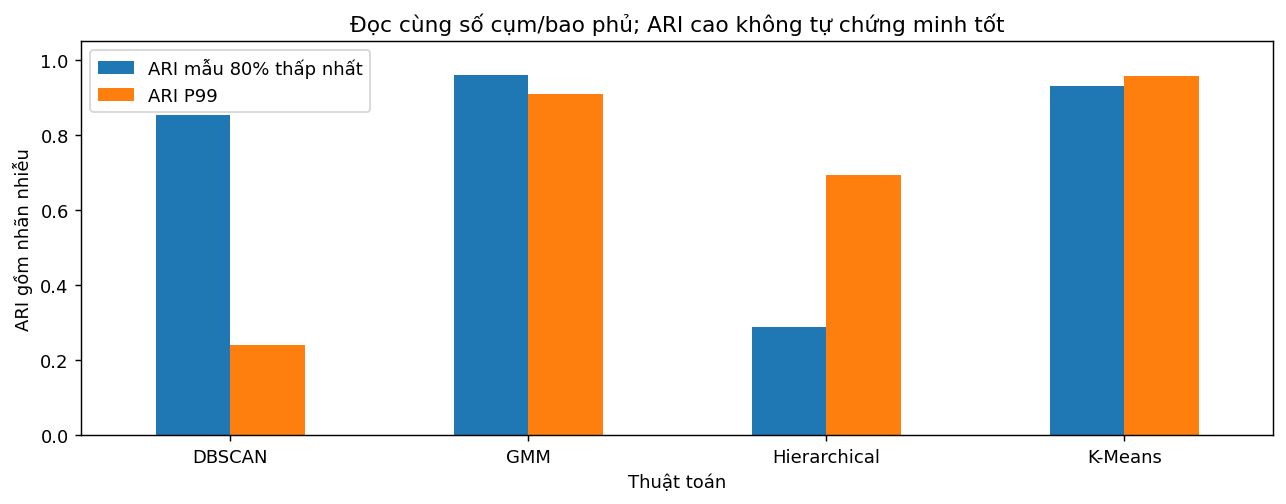

In [11]:
sensitivity_models = phan_cum_tich_hop().sensitivity_models
stability = sensitivity_models(ROOT, MODEL_LABEL)
study.table('four_model_sensitivity','Seed, mẫu 80%, P99, tham số và nhiễu', stability)
boundary = pd.read_csv(study.model_files(MODEL_LABEL)/'doi_chung/boundary_diagnostics.csv')
study.table('boundary_summary','Đặc trưng nhóm 5% margin thấp nhất', pd.DataFrame({
    'Toàn mẫu':boundary[FEATURES].median(),
    '5% margin thấp nhất':boundary.loc[boundary.selected_bottom5pct,FEATURES].median()
}).reset_index(names='feature'))
study.note('Nhóm gần ranh giới cần thận trọng khi áp dụng chính sách khác nhau; chưa có nhãn đúng để gọi là khách bị phân sai.')
plot_sensitivity = phan_cum_tich_hop().plot_sensitivity
study.fig('four_algorithm_stability','Độ nhạy thuật toán trên mẫu',plot_sensitivity(ROOT,MODEL_LABEL))


In [12]:
part_manifest=study.finish()

Hoàn thành: {'part': 'PC05', 'state': 'completed', 'model_run': 'combined_v1', 'tables': 11, 'figures': 2}


## Tài liệu phương pháp và phạm vi tham khảo

- [scikit-learn: K-Means và tổng quan phân cụm](https://scikit-learn.org/stable/modules/clustering.html#k-means).
- [StandardScaler: công thức và quy ước phương sai](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [Silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
- [Davies–Bouldin](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html).
- [Adjusted Rand Index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html).

Các nguồn trên giải thích phương pháp chung; không xác nhận ngữ nghĩa status/payment/delivery_date của bộ dữ liệu. Những định nghĩa nghiệp vụ dự án kế thừa hợp đồng GD2 và quyết định phạm vi đã công bố. Tên phiên bản thư viện chạy thực tế được lưu trong manifest, không suy từ phiên bản trang tài liệu hiện hành.
